# Q2. (d) Parameter Estimation in Logistic Regression

This section compares the maximum-likelihood estimate (MLE), which fits the data without regularization, with the maximum-a-posteriori estimate (MAP), which adds an L2 penalty representing a zero-mean Gaussian prior. The experiment uses the true weight vector \(w^* = [1.5, -2.0, 0.5]^T\) and the sample sizes specified in the assignment. The plot focuses on the first coefficient, \(w_1\), to show how each estimate behaves as the amount of data increases.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression

In [2]:
# INITIAL VARIABLES & CONFIGURATION

# True parameter values given in the question
TRUE_WEIGHTS = np.array([1.5, -2.0, 0.5])

# Sample sizes given in the question
SAMPLE_SIZES = [15, 25, 50, 100, 200, 400, 800, 1600, 3200, 6400, 12800]

# Use roll number as the random seed
DEFAULT_SEED = 2024090

In [3]:
def sigmoid(z: np.ndarray) -> np.ndarray:
    """
    Computes the sigmoid function: σ(z) = 1 / (1 + e^(-z))
    """
    # Clipping keeps exp() numerically stable for very large values.
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

In [4]:
def generate_synthetic_data(N: int, w_true: np.ndarray = TRUE_WEIGHTS, seed: int = DEFAULT_SEED) -> tuple[np.ndarray, np.ndarray]:
    """
    Generate features from a standard normal distribution and binary labels
    from the probabilities given by the true logistic model.
    """
    rng = np.random.default_rng(seed)
    d = len(w_true)
    X = rng.normal(0, 1, size=(N, d))
    logits = X @ w_true
    probabilities = sigmoid(logits)
    y = rng.binomial(1, probabilities)
    return X, y

In [5]:
def fit_models(X: np.ndarray, y: np.ndarray, C_map: float = 1.0) -> tuple[float, float]:
    """
    Fit an unregularized MLE model and an L2-regularized MAP model.
    """
    # MLE: no regularization
    mle_model = LogisticRegression(
        penalty=None, fit_intercept=False, solver="lbfgs", max_iter=10000
    )
    mle_model.fit(X, y)
    w1_mle = float(mle_model.coef_[0][0])

    # MAP: L2 regularization represents the Gaussian prior
    map_model = LogisticRegression(
        penalty="l2", C=C_map, fit_intercept=False, solver="lbfgs", max_iter=10000
    )
    map_model.fit(X, y)
    w1_map = float(map_model.coef_[0][0])
    return w1_mle, w1_map

In [6]:
def plot_convergence(sample_sizes: list[int] = SAMPLE_SIZES,
                     w1_mle_list: list[float] = None,
                     w1_map_list: list[float] = None,
                     w1_true: float = None):
    """
    Plot estimated first weights against sample size.
    """
    plt.figure(figsize=(10, 6))
    plt.semilogx(sample_sizes, w1_mle_list, marker="o", label="MLE estimate")
    plt.semilogx(sample_sizes, w1_map_list, marker="s", label="MAP estimate")
    plt.axhline(y=w1_true, color="black", linestyle="--", label=f"True w1 = {w1_true}")
    plt.xlabel("Sample size N (log scale)")
    plt.ylabel("Estimated first coefficient")
    plt.title("MLE and MAP convergence as sample size increases")
    plt.grid(True, which="both", alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

c:\Python314\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Python314\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Python314\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning

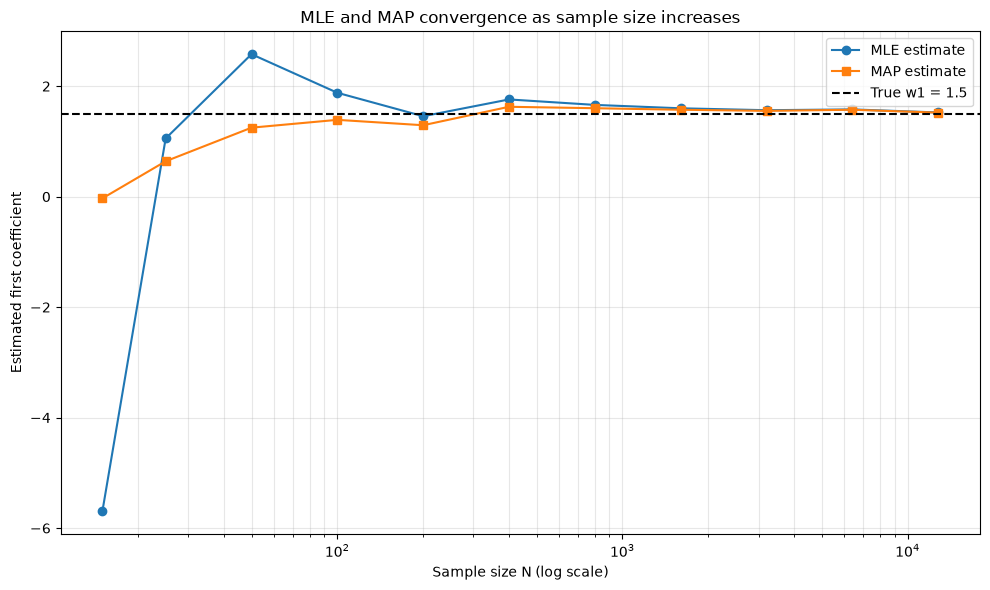

**Observation:** For small datasets, the estimated coefficient can differ noticeably from the true value because of sampling variation. As N increases, both estimates should generally move closer to the true coefficient 1.5. The MAP estimate is regularized, so it is usually pulled slightly toward zero.

In [7]:
# Store the estimates for each sample size
w1_mle_list = []
w1_map_list = []

for N in SAMPLE_SIZES:
    X_synthetic, y_synthetic = generate_synthetic_data(
        N=N, w_true=TRUE_WEIGHTS, seed=DEFAULT_SEED
    )
    w1_mle, w1_map = fit_models(X_synthetic, y_synthetic, C_map=1.0)
    w1_mle_list.append(w1_mle)
    w1_map_list.append(w1_map)

plot_convergence(
    sample_sizes=SAMPLE_SIZES,
    w1_mle_list=w1_mle_list,
    w1_map_list=w1_map_list,
    w1_true=TRUE_WEIGHTS[0]
)

from IPython.display import display, Markdown
display(Markdown(
    "**Observation:** For small datasets, the estimated coefficient can differ noticeably "
    "from the true value because of sampling variation. As N increases, both estimates "
    "should generally move closer to the true coefficient 1.5. The MAP estimate is "
    "regularized, so it is usually pulled slightly toward zero."
))

---

# Q3. Classification & Diagnostic Analysis with Logistic Regression

**Target dataset:** Scikit-learn Breast Cancer Diagnostic Dataset



In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    accuracy_score
)

In [9]:
# ============================================================
# 1. Load the Breast Cancer Diagnostic Dataset
# ============================================================

def load_breast_cancer_data():
    """Load the dataset and return features, labels, and their names."""
    dataset = load_breast_cancer()
    X = pd.DataFrame(dataset.data, columns=dataset.feature_names)
    y = pd.Series(dataset.target, name="target")
    feature_names = list(dataset.feature_names)
    target_names = list(dataset.target_names)
    return X, y, feature_names, target_names


X, y, feature_names, target_names = load_breast_cancer_data()

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Feature names:", feature_names)
print("Target names:", target_names)
display(X.head())

X shape: (569, 30)
y shape: (569,)
Feature names: [np.str_('mean radius'), np.str_('mean texture'), np.str_('mean perimeter'), np.str_('mean area'), np.str_('mean smoothness'), np.str_('mean compactness'), np.str_('mean concavity'), np.str_('mean concave points'), np.str_('mean symmetry'), np.str_('mean fractal dimension'), np.str_('radius error'), np.str_('texture error'), np.str_('perimeter error'), np.str_('area error'), np.str_('smoothness error'), np.str_('compactness error'), np.str_('concavity error'), np.str_('concave points error'), np.str_('symmetry error'), np.str_('fractal dimension error'), np.str_('worst radius'), np.str_('worst texture'), np.str_('worst perimeter'), np.str_('worst area'), np.str_('worst smoothness'), np.str_('worst compactness'), np.str_('worst concavity'), np.str_('worst concave points'), np.str_('worst symmetry'), np.str_('worst fractal dimension')]
Target names: [np.str_('malignant'), np.str_('benign')]


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## 1. Exploratory Data Analysis & Preprocessing

### 1.1 Class Distribution Check — 2.0 points

**Task:** Compute raw counts and percentages for each target class.

**Interpretation:** The dataset contains more benign than malignant cases, so the class distribution is not perfectly balanced. Reporting both counts and percentages makes the size of this difference clear. Because the less frequent malignant class is clinically important, accuracy alone would not be enough to judge the model; malignant-class recall must also be checked.


In [10]:
# Compute counts and percentages for each target class.

def class_distribution(y):
    """Return class counts and percentages with readable class names."""
    counts = y.value_counts().sort_index()
    percentages = (counts / len(y) * 100).round(2)
    class_names = {0: "Malignant", 1: "Benign"}
    distribution = pd.DataFrame({
        "Class": [class_names.get(int(label), str(label)) for label in counts.index],
        "Count": counts.values,
        "Percentage": percentages.values
    }, index=counts.index)
    distribution.index.name = "Target"
    return distribution


distribution = class_distribution(y)
display(distribution)
display(Markdown(
    "**Conclusion:** The dataset is somewhat imbalanced: benign cases are more common "
    "than malignant cases. The class counts should be considered when evaluating recall "
    "for malignant cases."
))

,Class,Count,Percentage
Target,,,
0,Malignant,212,37.26
1,Benign,357,62.74


**Conclusion:** The dataset is somewhat imbalanced: benign cases are more common than malignant cases. The class counts should be considered when evaluating recall for malignant cases.

### 1.2 Multicollinearity Analysis — 3.0 points

**Task:** Analyze the first 10 numerical features using their correlation matrix and heatmap.

**How to read the result:** A correlation close to +1 indicates a strong positive linear relationship, while a value close to -1 indicates a strong negative relationship. The code lists unique feature pairs with \(|r| > 0.85\), excluding each feature's correlation with itself.

**Why this matters:** Strongly correlated features contain overlapping information. Logistic regression may assign their shared effect across different coefficients, so individual coefficient values can become unstable and harder to interpret even when predictions remain useful.


In [11]:
# Select the first 10 numerical features.

def get_first_n_features(X, n=10):
    """Return the first n numerical columns."""
    numerical_X = X.select_dtypes(include=np.number)
    return numerical_X.iloc[:, :n]


X_first10 = get_first_n_features(X, n=10)
corr_matrix = X_first10.corr()
display(corr_matrix)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension
mean radius,1.000000,0.323782,0.997855,0.987357,0.170581,0.506124,0.676764,0.822529,0.147741,-0.311631
mean texture,0.323782,1.000000,0.329533,0.321086,-0.023389,0.236702,0.302418,0.293464,0.071401,-0.076437
mean perimeter,0.997855,0.329533,1.000000,0.986507,0.207278,0.556936,0.716136,0.850977,0.183027,-0.261477
mean area,0.987357,0.321086,0.986507,1.000000,0.177028,0.498502,0.685983,0.823269,0.151293,-0.283110
mean smoothness,0.170581,-0.023389,0.207278,0.177028,1.000000,0.659123,0.521984,0.553695,0.557775,0.584792
mean compactness,0.506124,0.236702,0.556936,0.498502,0.659123,1.000000,0.883121,0.831135,0.602641,0.565369
mean concavity,0.676764,0.302418,0.716136,0.685983,0.521984,0.883121,1.000000,0.921391,0.500667,0.336783
mean concave points,0.822529,0.293464,0.850977,0.823269,0.553695,0.831135,0.921391,1.000000,0.462497,0.166917
mean symmetry,0.147741,0.071401,0.183027,0.151293,0.557775,0.602641,0.500667,0.462497,1.000000,0.479921
mean fractal dimension,-0.311631,-0.076437,-0.261477,-0.283110,0.584792,0.565369,0.336783,0.166917,0.479921,1.000000


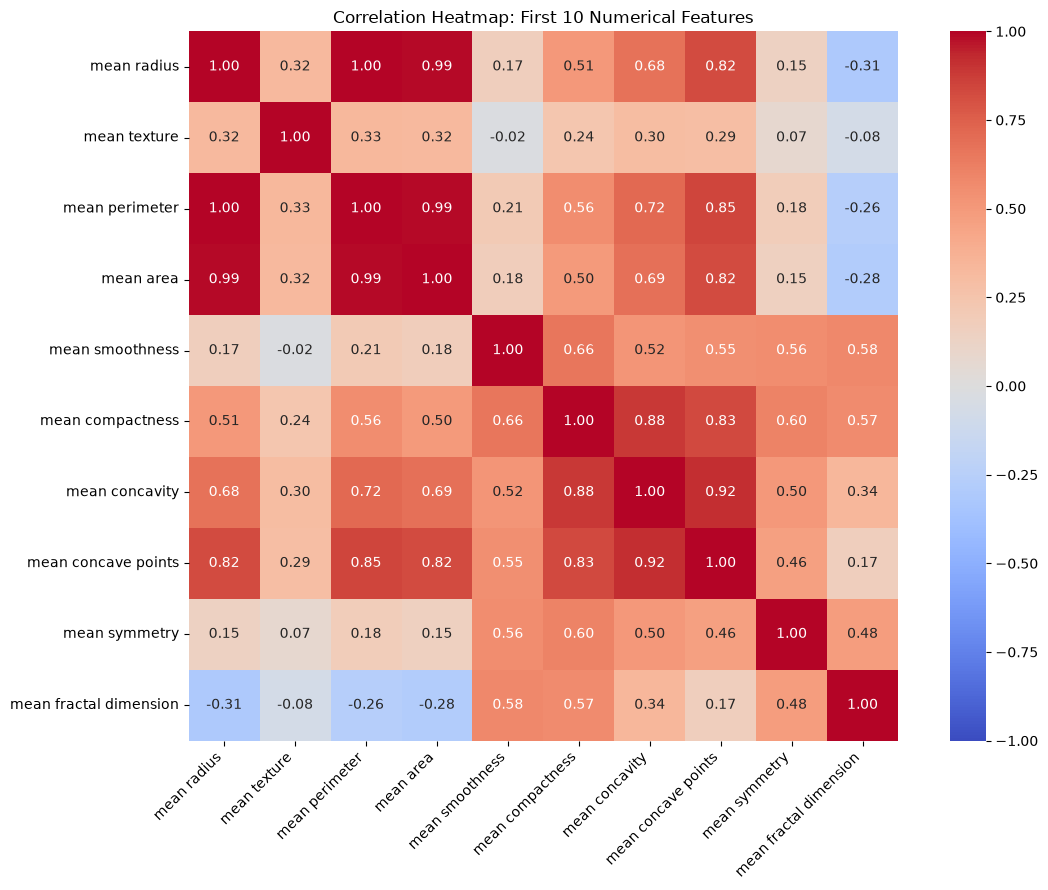

In [12]:
# Create the correlation heatmap.

def plot_correlation_heatmap(corr_matrix):
    """Plot an annotated heatmap of feature correlations."""
    plt.figure(figsize=(12, 9))
    sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm",
                vmin=-1, vmax=1, square=True)
    plt.title("Correlation Heatmap: First 10 Numerical Features")
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()


plot_correlation_heatmap(corr_matrix)

In [13]:
# Identify unique pairs with high absolute correlation.

def find_high_correlation_pairs(corr_matrix, threshold=0.85):
    """Return feature pairs whose absolute correlation exceeds threshold."""
    pairs = []
    columns = corr_matrix.columns
    for i in range(len(columns)):
        for j in range(i + 1, len(columns)):
            value = corr_matrix.iloc[i, j]
            if abs(value) > threshold:
                pairs.append({
                    "Feature 1": columns[i],
                    "Feature 2": columns[j],
                    "Correlation": value
                })
    return pd.DataFrame(pairs).sort_values(
        "Correlation", key=lambda values: values.abs(), ascending=False
    ).reset_index(drop=True)


high_corr_pairs = find_high_correlation_pairs(corr_matrix)
display(high_corr_pairs)
display(Markdown(
    "**Why this matters:** When features are strongly correlated, they contain overlapping "
    "information. The model can distribute their effects between coefficients in several "
    "ways, making individual coefficients unstable and harder to interpret, even when "
    "predictions are still reasonable."
))

,Feature 1,Feature 2,Correlation
0,mean radius,mean perimeter,0.997855
1,mean radius,mean area,0.987357
2,mean perimeter,mean area,0.986507
3,mean concavity,mean concave points,0.921391
4,mean compactness,mean concavity,0.883121
5,mean perimeter,mean concave points,0.850977


**Why this matters:** When features are strongly correlated, they contain overlapping information. The model can distribute their effects between coefficients in several ways, making individual coefficients unstable and harder to interpret, even when predictions are still reasonable.

### 1.3 Train-Test Split & Feature Scaling — 2 points

The data is split into 80% training and 20% test data, using stratification to preserve the class proportions in both sets. `StandardScaler` is fitted only on the training features (`fit_transform`) and then reused to transform the test features (`transform`). This prevents information from the test set influencing preprocessing and keeps the test set as an independent evaluation.


In [14]:
# Split first, then fit the scaler only on training data.

def split_and_scale(X, y, test_size=0.20, random_state=2024090):
    """Split data and standardize features without leaking test information."""
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=random_state, stratify=y
    )
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    return X_train_scaled, X_test_scaled, y_train, y_test, scaler


X_train_scaled, X_test_scaled, y_train, y_test, scaler = split_and_scale(
    X, y, test_size=0.20, random_state=2024090
)
print("Training shape:", X_train_scaled.shape)
print("Test shape:", X_test_scaled.shape)
display(Markdown(
    "**Why this split is used:** The scaler learns its means and standard deviations from "
    "the training set only. Applying those same values to the test set prevents information "
    "from the test data leaking into training and gives a fairer evaluation."
))

Training shape: (455, 30)
Test shape: (114, 30)


**Why this split is used:** The scaler learns its means and standard deviations from the training set only. Applying those same values to the test set prevents information from the test data leaking into training and gives a fairer evaluation.

## 2. Model Training & Feature Coefficient Analysis

### 2.1 Baseline Model Training — 1 point

A baseline logistic regression model is fitted on the standardized training features. The model uses L2 regularization with the default strength (`C=1.0`), which discourages excessively large coefficients and can improve stability when features are correlated. The test set is kept separate for the later diagnostic evaluation.


In [15]:
# Train the baseline logistic regression model.

def train_logistic_regression(X_train, y_train, penalty="l2", C=1.0,
                              solver="lbfgs", max_iter=1000):
    """Fit and return a logistic regression classifier."""
    model = LogisticRegression(
        penalty=penalty, C=C, solver=solver, max_iter=max_iter,
        random_state=2024090
    )
    model.fit(X_train, y_train)
    return model


baseline_model = train_logistic_regression(
    X_train_scaled, y_train, penalty="l2"
)
print("Baseline logistic regression model trained.")

Baseline logistic regression model trained.


c:\Python314\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


### 2.2 Odds Ratio Extraction — 6 points

The coefficient \(\beta\) is converted to an odds ratio using \(\exp(\beta)\). Since the inputs are standardized, a one-unit increase in a feature corresponds to a one-standard-deviation increase in that feature, holding the other features fixed.

- An odds ratio above 1 means the odds of class 1 (Benign) increase.
- An odds ratio below 1 means the odds of class 1 (Benign) decrease.
- An odds ratio near 1 indicates a relatively small change in the odds for a one-standard-deviation increase.

The table is sorted by absolute coefficient magnitude, and the chart separately shows the five most negative and five most positive coefficients. L2 regularization adds a squared-coefficient penalty to the fitting objective; it shrinks coefficient magnitudes toward zero and generally reduces instability, but does not usually make coefficients exactly zero.


In [16]:
# Build the coefficient/odds-ratio DataFrame.

def coefficient_odds_ratio_table(model, feature_names):
    """Return coefficients, odds ratios, and absolute coefficient magnitudes."""
    coefficients = model.coef_[0]
    table = pd.DataFrame({
        "Feature": list(feature_names),
        "Coefficient": coefficients,
        "Odds Ratio": np.exp(coefficients),
        "Absolute Coefficient": np.abs(coefficients)
    })
    return table.sort_values(
        "Absolute Coefficient", ascending=False
    ).reset_index(drop=True)


coef_table = coefficient_odds_ratio_table(baseline_model, X.columns)
display(coef_table)

,Feature,Coefficient,Odds Ratio,Absolute Coefficient
0,worst texture,-1.397347,0.247252,1.397347
1,radius error,-1.279379,0.278210,1.279379
2,worst radius,-0.996220,0.369273,0.996220
3,mean concave points,-0.935378,0.392438,0.935378
4,mean concavity,-0.925631,0.396281,0.925631
5,area error,-0.903036,0.405337,0.903036
6,worst symmetry,-0.891359,0.410098,0.891359
7,worst area,-0.889556,0.410838,0.889556
8,worst concave points,-0.888531,0.411260,0.888531
9,compactness error,0.802005,2.230008,0.802005


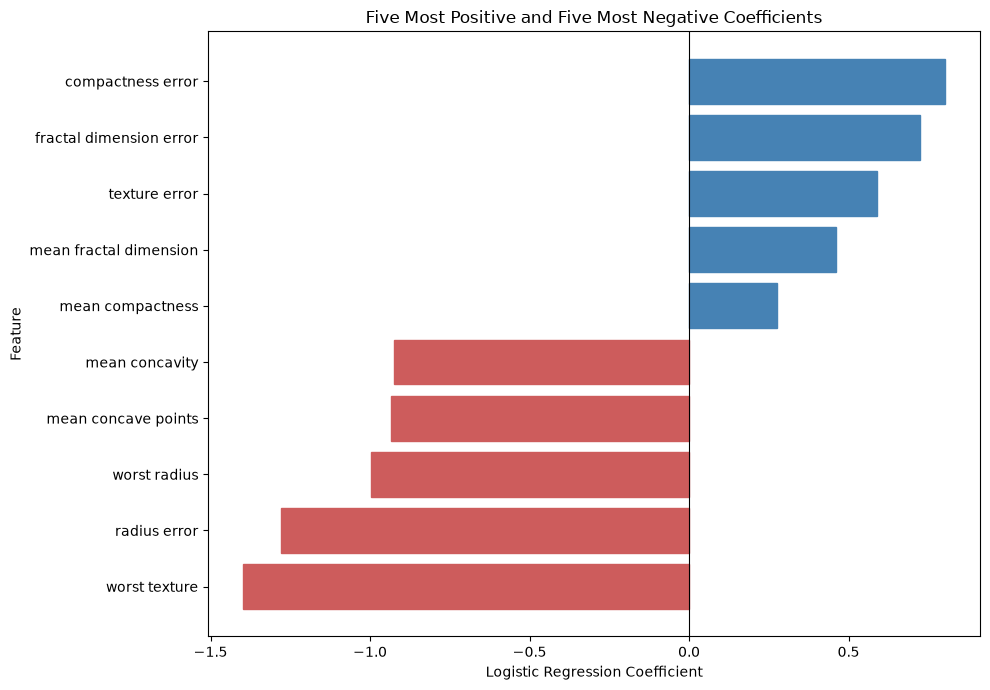

In [17]:
# Plot the 5 most positive and 5 most negative coefficients.

def plot_extreme_coefficients(coef_table, n=5):
    """Display the strongest positive and negative coefficients."""
    negative = coef_table.nsmallest(n, "Coefficient")
    positive = coef_table.nlargest(n, "Coefficient")
    extremes = pd.concat([negative, positive]).drop_duplicates("Feature")
    extremes = extremes.sort_values("Coefficient")
    plt.figure(figsize=(10, 7))
    bars = plt.barh(extremes["Feature"], extremes["Coefficient"])
    for bar, value in zip(bars, extremes["Coefficient"]):
        bar_color = "steelblue" if value >= 0 else "indianred"
        bar.set_color(bar_color)
    plt.axvline(0, color="black", linewidth=0.8)
    plt.xlabel("Logistic Regression Coefficient")
    plt.ylabel("Feature")
    plt.title("Five Most Positive and Five Most Negative Coefficients")
    plt.tight_layout()
    plt.show()


plot_extreme_coefficients(coef_table, n=5)

In [18]:
# Interpret one strongly negative coefficient.

def explain_negative_coefficient(coef_table):
    """Print the odds-ratio interpretation for the most negative coefficient."""
    row = coef_table.loc[coef_table["Coefficient"].idxmin()]
    coefficient = row["Coefficient"]
    odds_ratio = row["Odds Ratio"]
    change = (1 - odds_ratio) * 100
    print("Feature:", row["Feature"])
    print("Coefficient:", round(coefficient, 4))
    print("Odds ratio:", round(odds_ratio, 4))
    print(
        f"A one-standard-deviation increase in {row['Feature']} multiplies the odds "
        f"of the tumor being benign by {odds_ratio:.4f}."
    )
    if odds_ratio < 1:
        print(f"This is a decrease of about {change:.1f}% in the odds of class 1 (Benign).")
    else:
        print(f"This is an increase of about {(odds_ratio - 1) * 100:.1f}% in the odds of class 1 (Benign).")
    print(
        "L2 regularization discourages very large coefficients by adding a penalty, "
        "which can make estimates more stable when features are correlated."
    )
    return row


negative_feature = explain_negative_coefficient(coef_table)

Feature: worst texture
Coefficient: -1.3973
Odds ratio: 0.2473
A one-standard-deviation increase in worst texture multiplies the odds of the tumor being benign by 0.2473.
This is a decrease of about 75.3% in the odds of class 1 (Benign).
L2 regularization discourages very large coefficients by adding a penalty, which can make estimates more stable when features are correlated.


## 3. Diagnostics and Threshold Optimization

### 3.1 Default Threshold Evaluation (`p = 0.5`) — 3 points

The predicted probability returned by `predict_proba` is the probability of class 1 (Benign). At the default threshold of 0.5, probabilities at least 0.5 are classified as benign; lower probabilities are classified as malignant.

The confusion matrix uses the assignment's label convention: **0 = Malignant, 1 = Benign**. In this medical setting, a false negative for the malignant class means an actually malignant case is predicted as benign. This is generally the more dangerous error because it can delay further investigation or treatment. A false positive means a benign case is predicted as malignant and may lead to additional testing and anxiety, but is generally less dangerous than missing a malignant case.

The classification report provides class-specific precision, recall, and F1-score, so malignant recall can be evaluated directly rather than relying only on overall accuracy.


In [19]:
# Create a reusable prediction helper.

def get_predictions(model, X_test, threshold=0.50):
    """Return probability of class 1 (Benign) and threshold-based predictions."""
    probabilities = model.predict_proba(X_test)[:, 1]
    predictions = (probabilities >= threshold).astype(int)
    return probabilities, predictions


y_prob, y_pred_default = get_predictions(
    baseline_model, X_test_scaled, threshold=0.50
)

In [20]:
# Display the confusion matrix and classification report.

def evaluate_classifier(y_true, y_pred):
    """Show a labelled confusion matrix and class-wise metrics."""
    matrix = confusion_matrix(y_true, y_pred, labels=[0, 1])
    matrix_df = pd.DataFrame(
        matrix,
        index=["Actual Malignant (0)", "Actual Benign (1)"],
        columns=["Predicted Malignant (0)", "Predicted Benign (1)"]
    )
    display(matrix_df)
    print(classification_report(
        y_true, y_pred, labels=[0, 1],
        target_names=["Malignant (0)", "Benign (1)"], zero_division=0
    ))
    return matrix_df


default_confusion_matrix = evaluate_classifier(y_test, y_pred_default)
display(Markdown(
    "**Medical interpretation:** False negatives are more dangerous here. A false negative "
    "means a malignant tumor is predicted as benign, which can delay treatment. False "
    "positives can cause extra testing and anxiety, but are generally less dangerous than "
    "missing a malignant case."
))

,Predicted Malignant (0),Predicted Benign (1)
Actual Malignant (0),40,2
Actual Benign (1),0,72


               precision    recall  f1-score   support

Malignant (0)       1.00      0.95      0.98        42
   Benign (1)       0.97      1.00      0.99        72

     accuracy                           0.98       114
    macro avg       0.99      0.98      0.98       114
 weighted avg       0.98      0.98      0.98       114



**Medical interpretation:** False negatives are more dangerous here. A false negative means a malignant tumor is predicted as benign, which can delay treatment. False positives can cause extra testing and anxiety, but are generally less dangerous than missing a malignant case.

### 3.2 Custom Decision Threshold Optimization — 5 points

**Goal:** Test thresholds from `0.10` through `0.90` in increments of `0.05`, then choose a threshold that achieves at least **95% recall for the Malignant class** while maximizing **weighted overall precision** among thresholds that meet the recall requirement.

The model outputs the probability of class 1 (Benign), so lowering the threshold makes it easier to predict a case as benign, while raising it makes benign predictions less frequent and generally classifies more cases as malignant. The threshold therefore trades off the two classes' errors.

**Label detail:** Malignant is encoded as class `0`. The code calculates malignant recall explicitly with `pos_label=0`; it does not assume the default positive class is malignant. If multiple thresholds meet the recall constraint, the selected threshold is the one with the highest weighted precision. The final confusion matrix and class-wise report should be used to check the resulting trade-off.


In [21]:
# Evaluate thresholds and choose the best one that meets malignant recall >= 95%.

def evaluate_thresholds(y_true, y_prob,
                        thresholds=None,
                        malignant_label=0,
                        min_malignant_recall=0.95):
    """
    Evaluate thresholds using class-0 malignant recall and weighted precision.
    y_prob is the probability of class 1 (Benign).
    """
    if thresholds is None:
        thresholds = np.round(np.arange(0.10, 0.901, 0.05), 2)

    rows = []
    y_true_array = np.asarray(y_true)
    for threshold in thresholds:
        predictions = (np.asarray(y_prob) >= threshold).astype(int)
        malignant_recall = recall_score(
            y_true_array, predictions, pos_label=malignant_label, zero_division=0
        )
        overall_precision = precision_score(
            y_true_array, predictions, average="weighted", zero_division=0
        )
        rows.append({
            "Threshold": float(threshold),
            "Malignant Recall": malignant_recall,
            "Overall Precision": overall_precision,
            "Accuracy": accuracy_score(y_true_array, predictions)
        })

    results = pd.DataFrame(rows)
    candidates = results[results["Malignant Recall"] >= min_malignant_recall]
    if candidates.empty:
        best_row = None
        print("No tested threshold met the required malignant recall.")
    else:
        best_row = candidates.sort_values(
            ["Overall Precision", "Threshold"], ascending=[False, True]
        ).iloc[0]
    return results, best_row


threshold_results, best_threshold = evaluate_thresholds(
    y_test, y_prob, malignant_label=0, min_malignant_recall=0.95
)
display(threshold_results)
if best_threshold is not None:
    display(best_threshold.to_frame().T)
else:
    display(Markdown(
        "No threshold in the requested range achieved 95% malignant recall on this split."
    ))

,Threshold,Malignant Recall,Overall Precision,Accuracy
0,0.10,0.809524,0.936842,0.929825
1,0.15,0.809524,0.936842,0.929825
2,0.20,0.809524,0.936842,0.929825
3,0.25,0.833333,0.944037,0.938596
4,0.30,0.857143,0.951417,0.947368
5,0.35,0.904762,0.966759,0.964912
6,0.40,0.904762,0.966759,0.964912
7,0.45,0.928571,0.974737,0.973684
8,0.50,0.952381,0.982930,0.982456
9,0.55,0.976190,0.982456,0.982456


,Threshold,Malignant Recall,Overall Precision,Accuracy
8,0.5,0.952381,0.98293,0.982456


In [22]:
# Evaluate the final custom threshold.

def evaluate_custom_threshold(y_true, y_prob, threshold):
    """Generate predictions at a selected threshold and show diagnostics."""
    predictions = (np.asarray(y_prob) >= threshold).astype(int)
    print(f"Selected threshold: {threshold:.2f}")
    evaluate_classifier(y_true, predictions)
    print(
        "Malignant recall:",
        round(recall_score(y_true, predictions, pos_label=0, zero_division=0), 4)
    )
    return predictions


if best_threshold is not None:
    custom_predictions = evaluate_custom_threshold(
        y_test, y_prob, threshold=float(best_threshold["Threshold"])
    )
else:
    # Keep the notebook runnable if the recall constraint cannot be met.
    custom_predictions = evaluate_custom_threshold(y_test, y_prob, threshold=0.10)

Selected threshold: 0.50


,Predicted Malignant (0),Predicted Benign (1)
Actual Malignant (0),40,2
Actual Benign (1),0,72


               precision    recall  f1-score   support

Malignant (0)       1.00      0.95      0.98        42
   Benign (1)       0.97      1.00      0.99        72

     accuracy                           0.98       114
    macro avg       0.99      0.98      0.98       114
 weighted avg       0.98      0.98      0.98       114

Malignant recall: 0.9524
